In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Read the provided CSV
df = pd.read_csv('data.csv')
print(df.head())
print(df.shape)
print(df.columns)

   MATS3v  nHBint10  MATS3s  MATS3p  nHBDon_Lipinski  minHBint8  MATS3e  \
0  0.0908         0  0.0075  0.0173                0        0.0 -0.0436   
1  0.0213         0  0.1144 -0.0410                0        0.0  0.1231   
2  0.0018         0 -0.0156 -0.0765                2        0.0 -0.1138   
3 -0.0251         0 -0.0064 -0.0894                3        0.0 -0.0747   
4  0.0135         0  0.0424 -0.0353                0        0.0 -0.0638   

   MATS3c  minHBint2  MATS3m  ...   WTPT-4   WTPT-5  ETA_EtaP_L  ETA_EtaP_F  \
0  0.0409        0.0  0.1368  ...   0.0000   0.0000      0.1780      1.5488   
1 -0.0316        0.0  0.1318  ...   8.8660  19.3525      0.1739      1.3718   
2 -0.1791        0.0  0.0615  ...   5.2267  27.8796      0.1688      1.4395   
3 -0.1151        0.0  0.0361  ...   7.7896  24.7336      0.1702      1.4654   
4  0.0307        0.0  0.0306  ...  12.3240  19.7486      0.1789      1.4495   

   ETA_EtaP_B  nT5Ring  SHdNH  ETA_dEpsilon_C  MDEO-22     Class  
0      

In [4]:
#Summary Staistics
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Columns: 1204 entries, MATS3v to Class
dtypes: float64(1003), int64(200), object(1)
memory usage: 1.6+ MB
None
           MATS3v    nHBint10      MATS3s      MATS3p  nHBDon_Lipinski  \
count  171.000000  171.000000  171.000000  171.000000       171.000000   
mean    -0.031244    0.315789   -0.001001   -0.061501         0.994152   
std      0.063559    0.762918    0.063928    0.072891         1.108773   
min     -0.311500    0.000000   -0.184600   -0.348500         0.000000   
25%     -0.066700    0.000000   -0.036000   -0.099550         0.000000   
50%     -0.032500    0.000000   -0.002000   -0.059400         1.000000   
75%      0.004850    0.000000    0.029000   -0.017100         2.000000   
max      0.141100    4.000000    0.218100    0.129000         6.000000   

        minHBint8      MATS3e      MATS3c   minHBint2      MATS3m  ...  \
count  171.000000  171.000000  171.000000  171.000000  171.000000  ...   
me

Class
NonToxic    115
Toxic        56
Name: count, dtype: int64


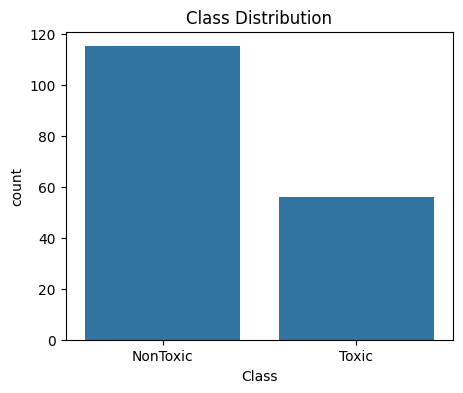

In [5]:
print(df["Class"].value_counts())

plt.figure(figsize=(5,4))
sns.countplot(x="Class", data=df)
plt.title("Class Distribution")
plt.show()

In [7]:
# Check Null Values
missing = df.isna().sum()

print(missing[missing > 0])

Series([], dtype: int64)


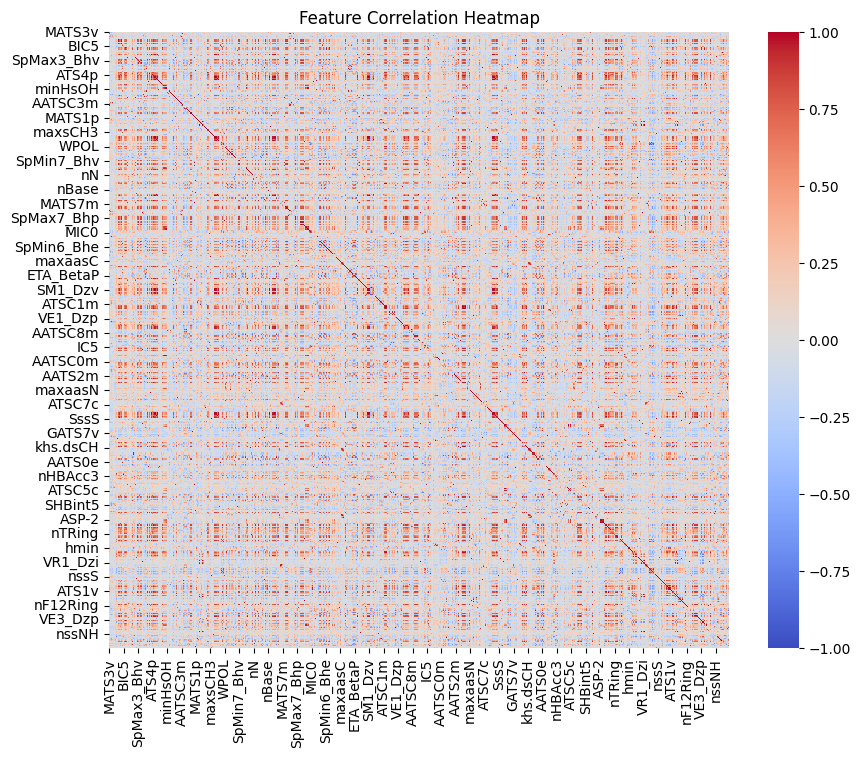

In [8]:
#Correlation heatmap(numerical features)
numeric_df = df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

In [9]:
#Separate features and Target
X = df.drop("Class", axis=1)
y = df["Class"]

In [10]:
#Encode target variable
le = LabelEncoder()
y = le.fit_transform(y)

print(pd.Series(y).value_counts())

0    115
1     56
Name: count, dtype: int64


In [11]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(136, 1203) (35, 1203)


In [12]:
#Feature selection
rf_temp = RandomForestClassifier(random_state=42)

rf_temp.fit(X_train, y_train)

importances = rf_temp.feature_importances_

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print(importance_df.head(10))

                Feature  Importance
782              GATS7c    0.007135
15           SpMax8_Bhi    0.006821
1102            VR2_Dzv    0.005877
269              MATS6c    0.005647
825          SpMin1_Bhv    0.005444
645               EE_Dt    0.004971
545              MATS5m    0.004958
859            SpMax_Dt    0.004853
1188  LipoaffinityIndex    0.004576
273             minssNH    0.004516


In [13]:
#Select top features
top_features = importance_df["Feature"].head(20)

X_train = X_train[top_features]
X_test = X_test[top_features]

In [14]:
#Build pipeline,this prevents data leakage
pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ))
])

In [15]:
#Cross-validation
cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Cross-Validation F1 Scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())

Cross-Validation F1 Scores: [0.375      0.44444444 0.47619048 0.52631579 0.15384615]
Mean CV F1: 0.39515937279095165


In [17]:
#Train final model
pipeline.fit(X_train, y_train)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('rf',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, random_state=42))])

In [18]:
#Predict on Test Data
y_pred = pipeline.predict(X_test)

In [19]:
#Model Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[20  4]
 [10  1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.83      0.74        24
           1       0.20      0.09      0.12        11

    accuracy                           0.60        35
   macro avg       0.43      0.46      0.43        35
weighted avg       0.52      0.60      0.55        35

